# Tools comparison

[W: Chinese Tools GenderGuesser](https://www.chinese-tools.com/tools/gender-guesser.html)

[R: ChineseNames R package](https://cran.r-project.org/web/packages/ChineseNames/ChineseNames.pdf)

[N: Namsor](https://namsor.app/)

In [1]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import vis
import tools_comparison
from tools_comparison import ToolsComparison
import categorical

In [2]:
VERSION = 2
DATA = f'../../data/v{VERSION}/chinese_names'
RESULTS = f'../../results/v{VERSION}/chinese_gender'

DIR_TOOL_W = ios.path_join(RESULTS, 'tool_w')
DIR_TOOL_R = ios.path_join(RESULTS, 'tool_r')
DIR_TOOL_N = ios.path_join(RESULTS, 'tool_n')
DIR_GT = ios.path_join(DATA, 'annotations')
DIR_PRED = ios.path_join(RESULTS, 'predictions')

## Data

In [3]:
tc = ToolsComparison(dir_tool_w=DIR_TOOL_W, dir_tool_r=DIR_TOOL_R, dir_tool_n=DIR_TOOL_N, dir_gt=DIR_GT)
tc.load_data()

In [4]:
tc.compare_unique_chinese_given_names()
tc.df_ch_genders.head(2)

,ngender_r,gender_w,0,1,2,3,4,5,6,7,...,std_ngender_rnw,std_ngender_rn,std_ngender_rw,std_ngender_nw,mode,mode_ngender_rnw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw,gender_nw
givenname,,,,,,,,,,,,,,,,,,,,,
俊池,0.30315,male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.161985,0.035063,0.151575,0.186638,NaN,0.30315,0.30315,0.30315,0.373277,male
建军,0.14830,male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.125561,0.079598,0.074150,0.153748,NaN,0.14830,0.14830,0.14830,0.307495,male


In [5]:
tc.df_ch_genders.query('gt==True')[['mean','median','mode']]

,mean,median,mode
givenname,,,
佳玉,0.909091,1.00,1.00
凤良,0.636364,0.75,1.00
璟,0.431818,0.50,0.50
怀珂,0.568182,0.50,0.75
馨心,0.977273,1.00,1.00
...,...,...,...
中锐,0.272727,0.25,0.25
能韫,0.227273,0.25,0.25
祖应,0.227273,0.25,0.25


In [6]:
tc.gt_cols

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [7]:
tc.df_ch_genders.shape

(39713, 40)

In [9]:
tc.save(DIR_PRED, tools_comparison.const.FN_CH_GIVEN_NAMES_GENDER)

## Overview

#### Categorical

In [8]:
FIGSIZE_SMALL = (5,3)

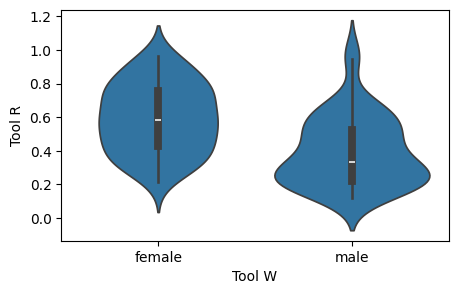

In [9]:
tool = 'w'
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool}', y='ngender_r', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool.upper()}', 
                ylabel='Tool R',
                )

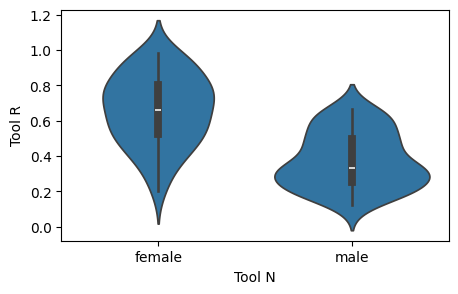

In [10]:
tool = 'n'
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool}', y='ngender_r', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool.upper()}', 
                ylabel='Tool R',
                )

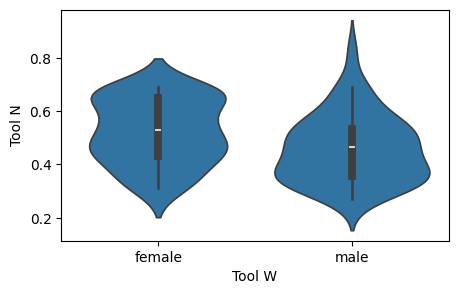

In [11]:
tool = 'w'
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool}', y='ngender_n', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool.upper()}', 
                ylabel='Tool N',
                )

#### Numerical

0.4390496536593299 0.2716806382865101


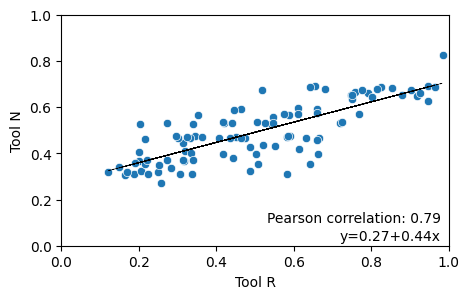

In [12]:
## scatter plot between namsor and R
tool_x = 'ngender_r'
tool_y = 'ngender_n'
vis.plot_scatter(df=tc.df_ch_genders_gt, x=tool_x, y=tool_y, figsize=(5, 3), 
                xlabel=f'Tool {tool_x.split('_')[-1].upper()}', 
                ylabel=f'Tool {tool_y.split('_')[-1].upper()}', 
                corr=True,
                fit=True,
                xlim=[0, 1], 
                ylim=[0, 1],
                )

## Index Performance

In [13]:
FIGSIZE = (5,3.1)
METRIC = 'mean' # GT

### Tool R

0.6583882214730289 0.16291329326751702


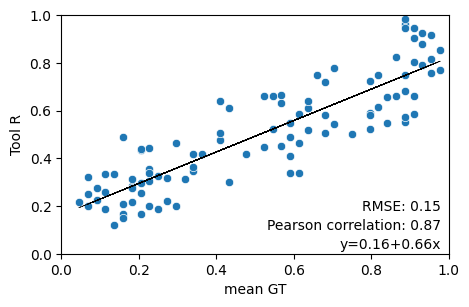

In [14]:
tool = 'r'
vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=f'ngender_{tool}', 
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'Tool {tool.upper()}', 
                 )

### Tool N

0.29678479373988853 0.33920220560098036


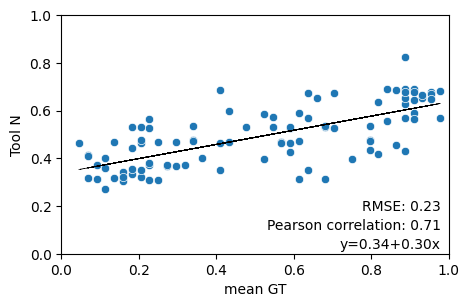

In [15]:
tool = 'n'
vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=f'ngender_{tool}', 
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'Tool {tool.upper()}', 
                 )


### Tool RNW 

0.618752290971356 0.19485861726436832


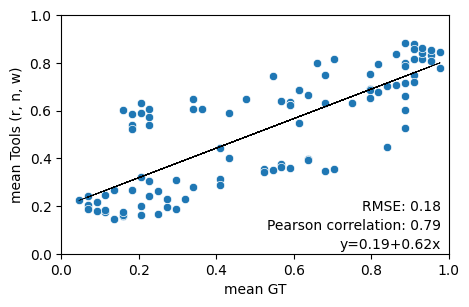

In [16]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

### Tool RN

0.4775865076064587 0.25105774943424874


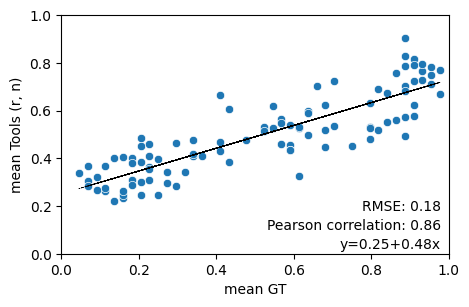

In [17]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

### Tool RW

0.7797360395870898 0.12268682309606227


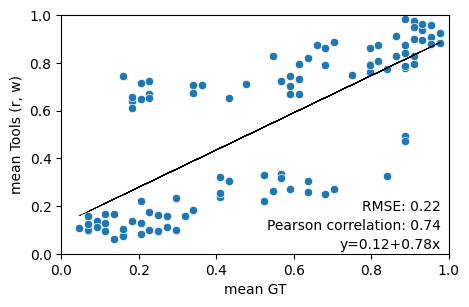

In [18]:
tools = 'rw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})', 
                 )


### Tool NW

0.5989343257205193 0.210831279262794


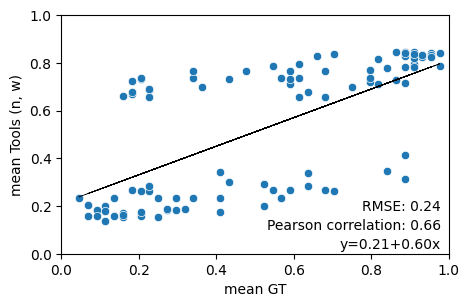

In [19]:
tools = 'nw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

## Categorical Performance

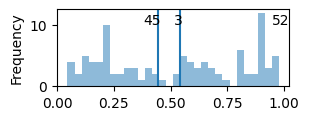

In [20]:
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, 'mean', bins=30, figsize=(3,1), cuts=[0.445, 0.541])

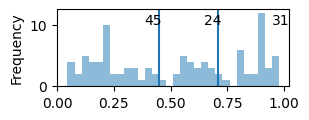

In [21]:
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, 'mean', bins=30, figsize=(3,1), cuts=[0.45, 0.71])

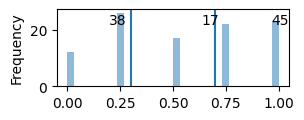

In [22]:
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, 'median', bins=30, figsize=(3,1), cuts=[0.3, 0.7])

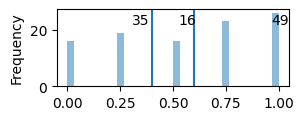

In [23]:
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, 'mode', bins=30, figsize=(3,1), cuts=[0.4, 0.6])

### Same thresholds

In [24]:
STRATEGY = {1:{'name':'arbitrary_cuts', 'cuts':[0.445, 0.541], 'gt_gender':'gender_mean', 'rot_fnc':categorical._get_gender_rot, 'rot_fnc_eq':categorical._get_gender_rot_equivalent},
            2:{'name':'arbitrary_cuts', 'cuts':[0.45, 0.71], 'gt_gender':'gender_mean', 'rot_fnc':categorical._get_gender_rot_all, 'rot_fnc_eq':categorical._get_gender_rot_all_equivalent},
            3:{'name':'arbitrary_cuts', 'cuts':[0.3, 0.7], 'gt_gender':'gender_median', 'rot_fnc':categorical._get_gender_rot_median, 'rot_fnc_eq':categorical._get_gender_rot_median_equivalent},
            4:{'name':'arbitrary_cuts', 'cuts':[0.4, 0.6], 'gt_gender':'gender_mode', 'rot_fnc':categorical._get_gender_rot_mode, 'rot_fnc_eq':categorical._get_gender_rot_mode_equivalent},
           }

In [25]:
STRATEGY_ID = 1

In [26]:
tc.df_ch_genders_gt[['ngender_r','ngender_n','ngender_w','mean_ngender_rw', 'median_ngender_rw', 'mode_ngender_rw']]

,ngender_r,ngender_n,ngender_w,mean_ngender_rw,median_ngender_rw,mode_ngender_rw
0,0.65875,0.589855,1.0,0.829375,0.829375,0.65875
1,0.51775,0.674656,0.0,0.258875,0.258875,0.51775
2,0.61075,0.597875,0.0,0.305375,0.305375,0.61075
3,0.44970,0.469505,1.0,0.724850,0.724850,0.44970
4,0.76760,0.570647,1.0,0.883800,0.883800,0.76760
...,...,...,...,...,...,...
95,0.22115,0.371490,0.0,0.110575,0.110575,0.22115
96,0.44305,0.378284,1.0,0.721525,0.721525,0.44305
97,0.30570,0.310454,1.0,0.652850,0.652850,0.30570
98,0.18925,0.358403,0.0,0.094625,0.094625,0.18925


In [27]:
cuts = STRATEGY[STRATEGY_ID]['cuts']
gt_gender = STRATEGY[STRATEGY_ID]['gt_gender']
rot_fnc = STRATEGY[STRATEGY_ID]['rot_fnc']
rot_fnc_eq = STRATEGY[STRATEGY_ID]['rot_fnc_eq']
cols = [gt_gender,'gender_rot','gender_r','gender_w','gender_n',  'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw', 'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all','ngender_r']
thresholds = [(-1,cuts[0]),(cuts[0],cuts[1]),(cuts[1],2)]
labels = categorical.GENDER_LABELS_3


df_sa = categorical.convert_numeric_to_categorical_by_thresholds(tc.df_ch_genders_gt, 
                                                                 thresholds=thresholds, 
                                                                 labels=labels, 
                                                                 rot_fnc=rot_fnc)
df_sa[cols].sort_values(cols[1:]).groupby(cols[:-1]).count()


ngender_r
gender_mean gender_rot gender_r gender_w gender_n gender_rn gender_rw gender_nw gender_rnw gender_mv_x1 gender_mv_x2 gender_mv_x1x2 gender_mv_all           
female      female     female   female   female   female    female    female    female     female       female       female         female                25
                                         male     female    female    female    female     female       female       female         female                 1
                                                  neutral   female    female    female     female       female       female         female                 7
                                male     female   female    male      male      male       female       male         female         male                   1
                                                                                neutral    female       male         female         female                 1
                                                            neutral   male      female     female       female       female         female                 1
                                                                                neutral    female       female       female         female                 1
                                                  neutral   male      male      male       female       male         male           male                   2
                       neutral  female   female   neutral   female    female    female     female       female       female         female                 1
                                         male     neutral   female    female    female     neutral      female       female         female                 4
                                male     female   female    male      male      male       neutral      male         male           male                   1
            male       male     female   female   male      female    female    female     female       female       female         female                 1
                                         male     male      female    female    female     male         female       male           female                 2
            neutral    female   male     male     female    male      male      male       male         male         male           male                   2
                       neutral  male     female   neutral   male      male      male       neutral      male         male           male                   2
male        female     female   male     female   female    male      male      male       female       male         female         male                   2
            male       male     female   female   neutral   female    female    female     female       female       female         female                 1
                                         male     male      female    female    female     male         female       male           female                 7
                                                                                neutral    male         female       male           male                   3
                                                  neutral   female    female    female     male         female       female         female                 1
                                male     female   male      male      male      male       male         male         male           male                   2
                                                  neutral   male      male      male       male         male         male           male                   2
                                         male     male      male      male      male       male         male         male           male                  23
                       neutral  female   male     male      female    female    female     neutral      female       female         female                 1
                                male     male     male      male 

In [28]:
df_comparison = categorical.comparison_metrics(df_sa,
                                               col_true=gt_gender, 
                                               labels=labels,
                                               cols_pred=['gender_r', 'gender_w', 'gender_n',
                                                          'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw',
                                                          'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all',
                                                          'gender_rot'])
df_comparison

/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capita

,gender_mean,gender_r,gender_w,gender_n,gender_rn,gender_rw,gender_nw,gender_rnw,gender_mv_x1,gender_mv_x2,gender_mv_x1x2,gender_mv_all,gender_rot
precision,"[1.0, 1.0, 1.0]","[0.91, 0.08, 0.93]","[0.71, 0.0, 0.75]","[0.69, 0.0, 0.8]","[0.92, 0.12, 0.94]","[0.74, 0.0, 0.75]","[0.71, 0.0, 0.75]","[0.76, 0.0, 0.79]","[0.89, 0.11, 0.91]","[0.74, 0.0, 0.75]","[0.78, 0.0, 0.88]","[0.78, 0.0, 0.8]","[0.91, 0.33, 0.96]"
recall,"[1.0, 1.0, 1.0]","[0.87, 0.33, 0.79]","[0.71, 0.0, 0.79]","[0.84, 0.0, 0.69]","[0.82, 1.0, 0.63]","[0.71, 0.0, 0.79]","[0.71, 0.0, 0.79]","[0.71, 0.0, 0.81]","[0.91, 0.33, 0.79]","[0.71, 0.0, 0.83]","[0.89, 0.0, 0.83]","[0.78, 0.0, 0.85]","[0.96, 0.67, 0.87]"
f1,"[1.0, 1.0, 1.0]","[0.89, 0.12, 0.85]","[0.71, 0.0, 0.77]","[0.76, 0.0, 0.74]","[0.87, 0.21, 0.76]","[0.73, 0.0, 0.77]","[0.71, 0.0, 0.77]","[0.74, 0.0, 0.8]","[0.9, 0.17, 0.85]","[0.73, 0.0, 0.79]","[0.83, 0.0, 0.85]","[0.78, 0.0, 0.82]","[0.93, 0.44, 0.91]"
auc,"[1.0, 1.0, 1.0]","[0.9, 0.6, 0.86]","[0.74, 0.5, 0.75]","[0.77, 0.5, 0.75]","[0.88, 0.89, 0.8]","[0.76, 0.49, 0.75]","[0.74, 0.5, 0.75]","[0.76, 0.47, 0.79]","[0.91, 0.63, 0.85]","[0.76, 0.5, 0.77]","[0.84, 0.5, 0.85]","[0.8, 0.5, 0.81]","[0.94, 0.81, 0.91]"
accuracy,1.0,0.81,0.73,0.74,0.73,0.73,0.73,0.74,0.83,0.75,0.83,0.79,0.9
n_male,45,43,45,55,40,43,45,42,46,43,51,45,47
n_neutral,3,13,0,0,25,2,0,5,9,0,0,0,6
n_female,52,44,55,45,35,55,55,53,45,57,49,55,47


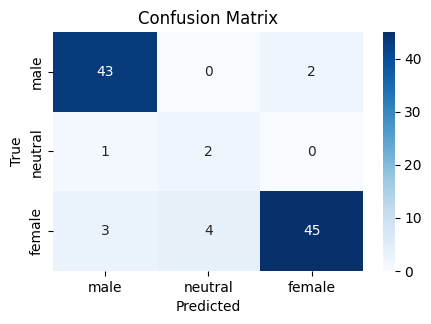

[0.91489362 0.33333333 0.95744681] [0.95555556 0.66666667 0.86538462] [0.93478261 0.44444444 0.90909091] [0.94141414 0.81271478 0.91185897] 0.9


In [29]:
col_pred = 'gender_rot'
normalize = None

cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_sa, 
                                                                       col_true=gt_gender, 
                                                                       col_pred=col_pred, 
                                                                       labels=labels, 
                                                                       normalize=normalize)
vis.plot_confusion_matrix(cm, labels, title='Confusion Matrix', cmap='Blues', figsize=FIGSIZE)
print(precision, recall, f1, auc, accuracy)

### Equivalent thresholds

In [30]:
ys = {'r':  [0.1629132932675171, 0.7182416961523954],
      'n':  [0.33920220560098047, 0.32376522953442416],
      'rnw':[0.19485861726436837, 0.6750024992414795],
      'rn': [0.25105774943424886, 0.5210034628434099],
      'rw': [0.12268682309606231, 0.8506211340950072],
      'nw': [0.21083127926279407, 0.6533829007860216]}

y = lambda x, tool: ys[tool][0] + (ys[tool][1] * x)
new_thresholds = lambda tool, thresholds: [(y(low,tool),y(high,tool)) for (low,high) in thresholds]

In [31]:
df_eq = categorical.convert_numeric_to_categorical_by_thresholds(tc.df_ch_genders_gt, 
                                                                 thresholds=thresholds, 
                                                                 labels=labels, 
                                                                 rot_fnc=rot_fnc_eq,
                                                                 new_trhesholds_fnc=new_thresholds,
                                                                 )

df_eq[cols].sort_values(cols[1:]).groupby(cols[:-1]).count()


ngender_r
gender_mean gender_rot gender_r gender_w gender_n gender_rn gender_rw gender_nw gender_rnw gender_mv_x1 gender_mv_x2 gender_mv_x1x2 gender_mv_all           
female      female     female   female   female   female    female    female    female     female       female       female         female                24
                                         male     female    female    female    female     female       female       female         female                 2
                                                  male      female    female    female     female       female       female         female                 1
                                                  neutral   female    female    female     female       female       female         female                 5
                                male     female   female    male      male      female     female       male         female         female                 1
                                                                                male       female       male         female         male                   2
                                                                                neutral    female       male         female         female                 1
                       male     female   female   neutral   female    female    female     female       female       female         female                 1
                       neutral  female   female   female    female    female    female     female       female       female         female                 1
                                         male     male      female    female    female     neutral      female       female         female                 3
                                male     female   female    male      male      male       neutral      male         male           male                   3
            male       male     female   female   male      female    female    female     female       female       female         female                 1
                                         male     male      female    female    female     male         female       male           female                 2
                                                                                neutral    male         female       male           male                   1
            neutral    female   male     male     female    male      male      male       male         male         male           male                   2
                       neutral  male     female   neutral   male      male      male       neutral      male         male           male                   2
male        female     female   male     female   female    male      male      male       female       male         female         male                   2
                       neutral  female   male     male      female    female    female     neutral      female       female         female                 1
            male       male     female   female   male      female    female    female     female       female       female         female                 1
                                         male     male      female    female    female     male         female       male           female                 8
                                                                                neutral    male         female       male           male                   3
                                male     female   male      male      male      male       male         male         male           male                   3
                                                  neutral   male      male      male       male         male         male           male                   1
                                         male     male      male      male      male       male         male         male           male                  25
                       neutral  male     male     male      male 

In [32]:
df_comparison_eq = categorical.comparison_metrics(df_eq,
                                                  col_true=gt_gender, 
                                                  labels=labels,
                                                  cols_pred=['gender_r', 'gender_w', 'gender_n',
                                                             'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw',
                                                             'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all',
                                                             'gender_rot'])
df_comparison_eq

/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capita

,gender_mean,gender_r,gender_w,gender_n,gender_rn,gender_rw,gender_nw,gender_rnw,gender_mv_x1,gender_mv_x2,gender_mv_x1x2,gender_mv_all,gender_rot
precision,"[1.0, 1.0, 1.0]","[0.85, 0.0, 0.93]","[0.71, 0.0, 0.75]","[0.69, 0.0, 0.8]","[0.82, 0.18, 0.95]","[0.71, 0.0, 0.75]","[0.71, 0.0, 0.75]","[0.74, 0.0, 0.79]","[0.85, 0.0, 0.91]","[0.71, 0.0, 0.75]","[0.77, 0.0, 0.89]","[0.74, 0.0, 0.79]","[0.88, 0.2, 0.94]"
recall,"[1.0, 1.0, 1.0]","[0.91, 0.0, 0.73]","[0.71, 0.0, 0.79]","[0.84, 0.0, 0.69]","[0.93, 0.67, 0.69]","[0.71, 0.0, 0.79]","[0.71, 0.0, 0.79]","[0.71, 0.0, 0.79]","[0.91, 0.0, 0.75]","[0.71, 0.0, 0.79]","[0.91, 0.0, 0.81]","[0.78, 0.0, 0.81]","[0.93, 0.33, 0.85]"
f1,"[1.0, 1.0, 1.0]","[0.88, 0.0, 0.82]","[0.71, 0.0, 0.77]","[0.76, 0.0, 0.74]","[0.88, 0.29, 0.8]","[0.71, 0.0, 0.77]","[0.71, 0.0, 0.77]","[0.73, 0.0, 0.79]","[0.88, 0.0, 0.82]","[0.71, 0.0, 0.77]","[0.84, 0.0, 0.85]","[0.76, 0.0, 0.8]","[0.9, 0.25, 0.89]"
auc,"[1.0, 1.0, 1.0]","[0.89, 0.44, 0.83]","[0.74, 0.5, 0.75]","[0.77, 0.5, 0.75]","[0.88, 0.79, 0.83]","[0.74, 0.5, 0.75]","[0.74, 0.5, 0.75]","[0.76, 0.47, 0.78]","[0.89, 0.45, 0.83]","[0.74, 0.5, 0.75]","[0.85, 0.5, 0.85]","[0.78, 0.5, 0.79]","[0.91, 0.65, 0.89]"
accuracy,1.0,0.79,0.73,0.74,0.8,0.73,0.73,0.73,0.8,0.73,0.83,0.77,0.87
n_male,45,48,45,55,51,45,45,43,48,45,53,47,48
n_neutral,3,11,0,0,11,0,0,5,9,0,0,0,5
n_female,52,41,55,45,38,55,55,52,43,55,47,53,47


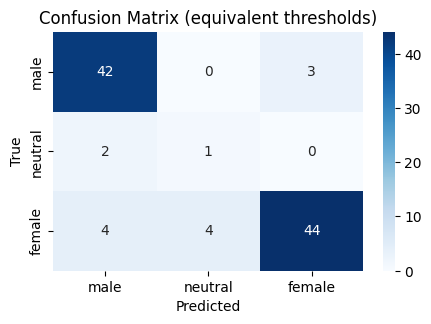

[0.875      0.2        0.93617021] [0.93333333 0.33333333 0.84615385] [0.90322581 0.25       0.88888889] [0.91212121 0.64604811 0.89182692] 0.87


In [33]:
col_pred = 'gender_rot'
cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_eq, 
                                                                       col_true=gt_gender, 
                                                                       col_pred=col_pred, 
                                                                       labels=labels, 
                                                                       normalize=normalize)
vis.plot_confusion_matrix(cm, labels, title='Confusion Matrix (equivalent thresholds)', cmap='Reds', figsize=FIGSIZE)
print(precision, recall, f1, auc, accuracy)

In [38]:
## Features
import setup
setup.FEATURES

['ngender_r',
 'ngender_n',
 'gender_w',
 'gender_n',
 'gender_nw',
 'mean_ngender_rn',
 'mean_ngender_rw',
 'mean_ngender_nw',
 'mean_ngender_rnw']

In [43]:
from itertools import combinations

items = setup.FEATURES
all_combinations = []

# Generate combinations of different sizes
for r in range(1, len(items) + 1):
    for comb in combinations(items, r):
        # Exclude combinations that contain both "item 8" and "item 10"
        if not ("ngender_n" in comb and "gender_n" in comb):
            all_combinations.append(list(comb))

# Print the number of combinations
print("Total combinations:", len(all_combinations))

# Print all combinations
for comb in all_combinations:
    print(comb)

    # 511 total (388 without the ngender_n, gender_n)


Total combinations: 255
['ngender_r']
['ngender_n']
['gender_w']
['gender_nw']
['mean_ngender_rn']
['mean_ngender_rw']
['mean_ngender_nw']
['mean_ngender_rnw']
['ngender_r', 'ngender_n']
['ngender_r', 'gender_w']
['ngender_r', 'gender_nw']
['ngender_r', 'mean_ngender_rn']
['ngender_r', 'mean_ngender_rw']
['ngender_r', 'mean_ngender_nw']
['ngender_r', 'mean_ngender_rnw']
['ngender_n', 'gender_w']
['ngender_n', 'gender_nw']
['ngender_n', 'mean_ngender_rn']
['ngender_n', 'mean_ngender_rw']
['ngender_n', 'mean_ngender_nw']
['ngender_n', 'mean_ngender_rnw']
['gender_w', 'gender_nw']
['gender_w', 'mean_ngender_rn']
['gender_w', 'mean_ngender_rw']
['gender_w', 'mean_ngender_nw']
['gender_w', 'mean_ngender_rnw']
['gender_nw', 'mean_ngender_rn']
['gender_nw', 'mean_ngender_rw']
['gender_nw', 'mean_ngender_nw']
['gender_nw', 'mean_ngender_rnw']
['mean_ngender_rn', 'mean_ngender_rw']
['mean_ngender_rn', 'mean_ngender_nw']
['mean_ngender_rn', 'mean_ngender_rnw']
['mean_ngender_rw', 'mean_ngender_n

___

# OLD

#### Majority voting (tools)

In [ ]:
tool = 'r'
column = f'ngender_{tool}'
n_categories = 2
labels = GENDER_LABELS_2

tc.df_ch_genders_gt.loc[:,f'gender_{tool}'] = tools_comparison.pd.cut(tc.df_ch_genders_gt[column], bins=n_categories, labels=labels, right=True, precision=2, include_lowest=True)


# tc.df_ch_genders_gt.loc[:,f'majority_voting_nrw'] = tools_comparison.get_majority_voting(tc.df_ch_genders_gt, ['gender','',''], n_categories)
tc.df_ch_genders_gt.loc[:,'gender_rnw'] = tc.df_ch_genders_gt.apply(lambda row: row['gender_n'] if row['gender_n'] == row['gender_w'] and row['gender_n'] == row['gender_r'] else 
                                                                                f"mostly_{row['gender_n']}" if row['gender_n'] == row['gender_w'] else
                                                                                f"mostly_{row['gender_n']}" if row['gender_n'] == row['gender_r'] else
                                                                                f"mostly_{row['gender_r']}" if row['gender_r'] == row['gender_w'] else NEUTRAL, axis=1)

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 hue='gender_rnw',
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )


In [ ]:
# # get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=metric, labels_fnc=labels_fnc, 
                                                                                                                        bins_gt = bins_x,
                                                                                                                        bins_tools = bins_y)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=FIGSIZE)

# # plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=FIGSIZE)

# # plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=FIGSIZE)

# # plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=FIGSIZE)

### Per tool

##### Tool R

In [ ]:
column = 'ngender_r'
get_label_fnc = get_label_3classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
column = 'ngender_r'
get_label_fnc = get_label_5classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

##### Tools RN

In [ ]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_3classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_5classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

##### Tools RNW
all three

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_3classes

best_thresholds = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_5classes

best_thresholds = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)